# Two related Polymarket ladders: a blockade and a ceasefire

Two ladders of contracts on Polymarket, priced on 20 November 2026:

- **A** — *US announces end of Iranian blockade by …?* (one contract per date,
  from 30 November 2026 to 31 March 2027);
- **B** — *Israel x Iran ceasefire continues through …?* (one contract per date,
  from 20 November to 31 December 2026).

Each ladder prices the distribution of a **time to an event**. This notebook
models both ladders with hazard rates and asks how the two events depend on
each other, with two models:

1. a **latent factor**: the hazards of both events share drivers that move over
   time; estimated from the price history of all 74 contracts since July;
2. a **four-state Markov chain**: each event changes the hazard of the other
   (if the ceasefire breaks, the blockade is less, or more, likely to end).

The data were downloaded from Polymarket's public API (`gamma-api` for the
markets, `clob` for daily price histories) and saved in `data/`; the notebook
runs offline. The models, with their exact gradients and Hessians, are in
[`polymarket_models.py`](polymarket_models.py).

*Prices are not probabilities: they include fees, a risk premium, and the
risk of an ambiguous resolution. They are treated as probabilities below.*

## 1. Theory

### Hazard rates and ladders

Let $T_A$ be the time of the announcement and $T_B$ the time the ceasefire
breaks. With hazard $h(t)$ and cumulative hazard $H(t) = \int_{t_0}^{t} h$,

$$
q^A_k \approx P(T_A \le t_k) = 1 - e^{-H_A(t_k)},
\qquad
q^B_k \approx P(T_B > t_k) = e^{-H_B(t_k)} .
$$

With a hazard constant between deadlines, $h_X(t) = e^{a_{X,j}}$ on
$(t_{j-1}, t_j]$, a ladder of $K$ prices gives $K$ hazards, read off one
deadline at a time. This **complementary log-log** scale,
$\log H = \log(-\log S)$, is the natural one for times to events: on it a
change of the hazard is a shift, whatever the maturity. Contracts with
different maturities are compared through the hazard of the calendar days
they cover, never price against price.

### Model 1 — latent factor with temporal structure

**History.** On day $d$ the market's hazard curve for ladder $X$ is a
calendar baseline times a multiplier of the day:

$$
h_X(t \mid d) = \exp\big(a_X[\mathrm{bin}(t)] + m_X(d)\big),
\qquad
H_{X,o} = e^{m_X(d_o)} \sum_j L_{oj}\, e^{a_{X,j}},
$$

where $L_{oj}$ is the number of days of bin $j$ between the day of
observation $o$ and its deadline. The multipliers follow random walks,

$$
m_X(d) = m_X(d-1) + \eta_{X,d}, \qquad \eta_d \sim \mathcal N(0, \Sigma),
$$

and are estimated by maximising the binomial Kullback–Leibler fit to every
daily price, $\sum_o \big[q_o \log p_o + (1-q_o)\log(1-p_o)\big]$, minus the
random-walk penalties $\lambda \sum_d (m_X(d) - m_X(d-1))^2$ (a Gaussian prior
on the steps) and a smoothness penalty on the baselines. $m_X(\text{today}) = 0$
identifies the levels. The dependence between the two events is the
**correlation of the changes** $\Delta m_A, \Delta m_B$, and the temporal
structure is checked with $\mathrm{var}(m(d+h) - m(d))/h$: constant in $h$ for
a random walk, falling for a mean-reverting factor.

**The correlation as a parameter.** Correlating the changes of the
estimated $\hat m_A, \hat m_B$ is a two-step shortcut, biased towards zero:
the separate random-walk penalties pull the two series apart, and price noise
leaks into $\hat m$. The model proper is a Gaussian state-space model on the
complementary log-log scale. With $\hat a$ the fitted baselines,

$$
r_o = \log H_o^{\text{market}} - \log \sum_j L_{oj} e^{\hat a_{X,j}} = m_X(d_o) + \varepsilon_o,
\qquad
\mathrm{sd}(\varepsilon_o) = \frac{\tau}{H_o e^{-H_o}},
$$

that is, price noise of $\tau$ (in probability points) carried to that scale by
the delta method, and

$$
\Sigma = \begin{pmatrix} s_A^2 & \rho\, s_A s_B \\ \rho\, s_A s_B & s_B^2 \end{pmatrix} .
$$

The states integrate out exactly: $r \sim \mathcal N\big(0,\ Z K(\Sigma) Z^\top + R(\tau)\big)$,
with $K$ the covariance of the anchored random walk ($m(\text{today}) = 0$). So
$(s_A, s_B, \rho, \tau)$ are estimated by maximum likelihood, and a confidence
interval for $\rho$ comes from its profile likelihood.

**Forward.** From today, $W(t) = (W_A, W_B)$ is a bivariate random walk with
covariance $\Sigma$ per day, $W(t_0) = 0$, and given a path the events are
independent:

$$
H_X(t) = \sum_j e^{a_{X,j}} \int_{\mathrm{bin}\ j,\ s \le t} e^{W_X(s)}\,ds,
\qquad
p^A_k = \mathbb E\big[1 - e^{-H_A(t_k)}\big],\quad
p^B_k = \mathbb E\big[e^{-H_B(t_k)}\big].
$$

The baselines are fitted so that these averages, over simulated paths, match
today's prices exactly. The joint law then follows from the same paths,

$$
P(T_A \le t,\ T_B \le s) = \mathbb E\big[(1 - e^{-H_A(t)})(1 - e^{-H_B(s)})\big] .
$$

### Model 2 — four-state Markov chain

States (ceasefire, blockade):
$0 = (\text{on}, \text{on})$, $1 = (\text{on}, \text{ended})$,
$2 = (\text{broken}, \text{on})$, $3 = (\text{broken}, \text{ended})$, with intensities

| transition | intensity |
|---|---|
| $0 \to 1$, blockade ends | $h_A(t)$ |
| $0 \to 2$, ceasefire breaks | $h_B(t)$ |
| $2 \to 3$, blockade ends after the ceasefire broke | $\rho\, h_A(t)$ |
| $1 \to 3$, ceasefire breaks after the blockade ended | $\kappa\, h_B(t)$ |

On steps of $\delta = 6$ hours, $\pi_{n+1} = \pi_n M_n$, with
$M_n$ built from $e^{-h\delta}$ terms, and

$$
p^A_k = \pi_1(t_k) + \pi_3(t_k), \qquad p^B_k = \pi_0(t_k) + \pi_1(t_k) .
$$

The derivatives propagate with the chain:
$\partial\pi_{n+1} = \partial\pi_n M_n + \pi_n\,\partial M_n$ and
$\partial^2\pi_{n+1} = \partial^2\pi_n M_n + \partial\pi_n\,\partial M_n^\top + \partial M_n\,\partial\pi_n^\top + \pi_n\,\partial^2 M_n$.

### What the prices identify

Each ladder has as many prices as hazards, so the **marginals are fitted
exactly by both models, whatever the dependence**. Today's prices alone say
nothing about $\rho$, $\kappa$ or the correlation of the factor: the history
(model 1) or a judgement (model 2) must.

### Fitting with `maxlike`

Each objective, with its exact gradient and Hessian, is wrapped as a
`DenseObjective` (a `Func` with one observation) and fitted by
`maxlike.LogLikelihood` with Newton's method; fixed parameters (today's
multipliers, $\rho$ and $\kappa$ in model 2) use `add_param(..., fixed)`.
All three objectives are checked against finite differences below.

In [1]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import brentq

import plot_style as ps          # also puts the package and the examples on the path
from plot_style import BLUE, ORANGE, AQUA, TEXT_2, SEQUENTIAL
import polymarket_models as pm

ps.apply()
warnings.filterwarnings("ignore", category=RuntimeWarning)
DAY = np.timedelta64(1, "D")


def date_label(deadline, fmt="%d %b"):
    """the date in the question (deadlines are stored at the end of that
    day in US Eastern time, as UTC)"""
    return pd.DatetimeIndex(np.atleast_1d(deadline)).shift(-28, "h").strftime(fmt) \
        if np.ndim(deadline) else (pd.Timestamp(deadline) - pd.Timedelta(hours=28)).strftime(fmt)

hist = pd.read_csv("data/polymarket_iran_history.csv", parse_dates=["deadline", "time"])
snap = pd.read_csv("data/polymarket_iran_snapshot.csv", parse_dates=["deadline"])
t0 = hist["time"].max()
snap["mid"] = (snap["bid"] + snap["ask"]) / 2
A, B = snap[snap.ladder == "blockade"], snap[snap.ladder == "ceasefire"]
qA, qB = A["mid"].values, B["mid"].values
deadlines = [A["deadline"].values, B["deadline"].values]
print("prices as of", t0, "UTC;", len(hist), "daily prices of",
      hist.groupby(["ladder", "deadline"]).ngroups, "contracts")
snap[["question", "bid", "ask", "volume"]].round(3)

prices as of 2026-11-20 04:35:12 UTC; 1412 daily prices of 74 contracts


,question,bid,ask,volume
0,US announces end of Iranian blockade by Novemb...,0.030,0.031,3692083.252
1,US announces end of Iranian blockade by Decemb...,0.070,0.080,80708.724
2,US announces end of Iranian blockade by Decemb...,0.112,0.119,6805930.348
3,US announces end of Iranian blockade by Januar...,0.220,0.230,12936.343
4,US announces end of Iranian blockade by Februa...,0.320,0.330,1642.441
5,US announces end of Iranian blockade by March ...,0.430,0.440,763786.431
6,Israel x Iran ceasefire continues through Nove...,0.985,0.987,651534.710
7,Israel x Iran ceasefire continues through Nove...,0.930,0.940,1865315.693
8,Israel x Iran ceasefire continues through Nove...,0.830,0.840,1986484.234
9,Israel x Iran ceasefire continues through Dece...,0.720,0.730,1152418.704


## 2. Data

**Today's ladders.** Probability of each event by each deadline, with the
bid–ask spread, and the hazard each step implies: the probability per day that
the event happens, given it has not yet.

,event,period,"hazard, % per day"
0,blockade ends,to 30 Nov,0.28
1,blockade ends,to 15 Dec,0.31
2,blockade ends,to 31 Dec,0.28
3,blockade ends,to 31 Jan,0.43
4,blockade ends,to 28 Feb,0.49
5,blockade ends,to 31 Mar,0.57
6,ceasefire breaks,to 20 Nov,1.45
7,ceasefire breaks,to 22 Nov,2.66
8,ceasefire breaks,to 30 Nov,1.41
9,ceasefire breaks,to 15 Dec,0.94


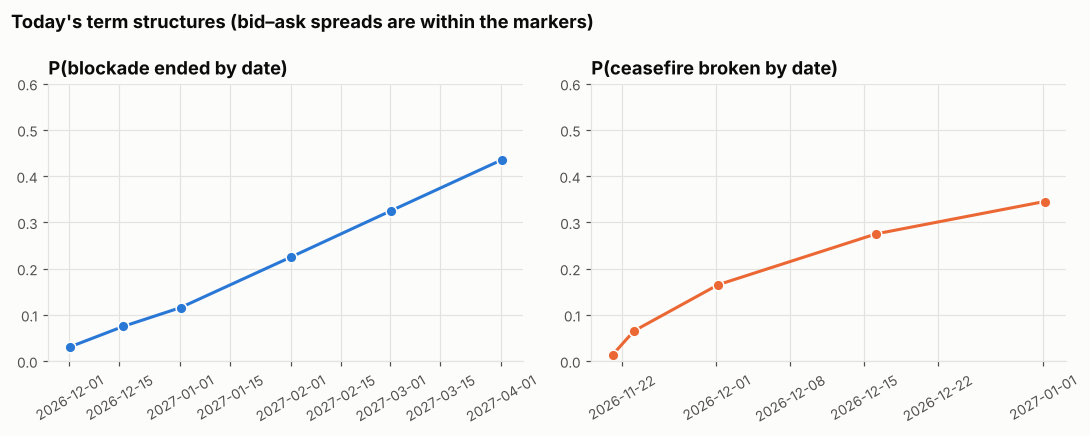

In [2]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, d, q, label, color in ((axes[0], A, qA, "P(blockade ended by date)", BLUE),
                               (axes[1], B, 1 - qB, "P(ceasefire broken by date)", ORANGE)):
    x = d["deadline"]
    lo = d["bid"] if d is A else 1 - d["ask"]
    hi = d["ask"] if d is A else 1 - d["bid"]
    ax.plot(x, q, "o-", color=color, markersize=7, markeredgecolor="#fcfcfb")
    ax.vlines(x, lo, hi, color=color, lw=3, alpha=.4)
    ax.set_ylim(0, 0.6)
    ax.set_title(label)
    ax.tick_params(axis="x", rotation=30)
fig.suptitle("Today's term structures (bid–ask spreads are within the markers)", x=0.01, ha="left",
             fontweight="bold")
plt.tight_layout()

rows = []
for name, d, H in (("blockade ends", A, -np.log1p(-qA)), ("ceasefire breaks", B, -np.log(qB))):
    tk = (d["deadline"].values - np.datetime64(t0)) / DAY
    rate = np.diff(np.concatenate([[0], H])) / np.diff(np.concatenate([[0], tk]))
    for dl, r in zip(date_label(d["deadline"]), rate):
        rows.append((name, "to " + dl, 100 * r))
pd.DataFrame(rows, columns=["event", "period", "hazard, % per day"]).round(2)

The ceasefire market prices a sharp risk in the next few days (about 1.5% for
today, then 2.7% a day until 22 November), falling to 1.4% a day to the end of
November and 0.6–0.9% a day in December. The blockade market prices about 0.3%
a day until the end of the year, rising to 0.4–0.6% a day in 2027.

**History.** Since July the prices have moved a lot: in August the market gave
about 90% to an end of the blockade by 31 December; today it gives 11%.

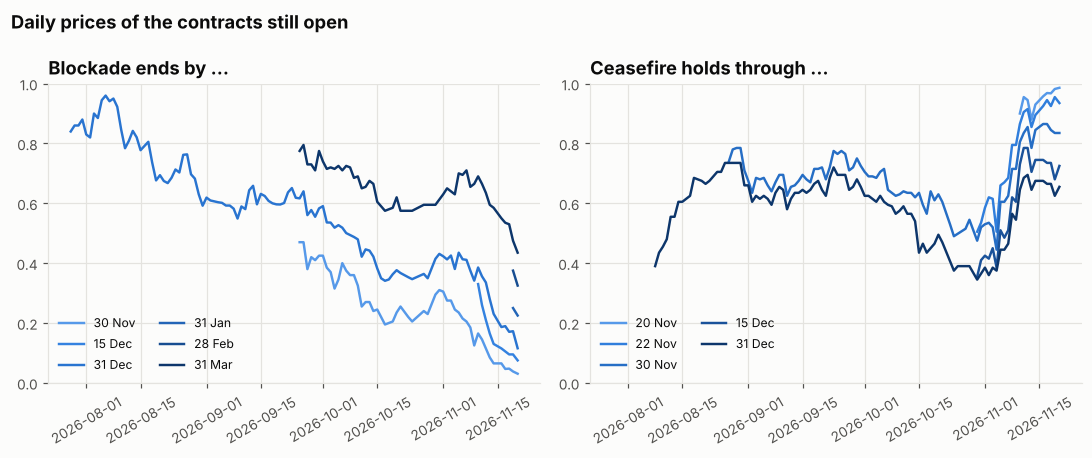

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4.2), sharex=True)
for ax, lad, title in ((axes[0], "blockade", "Blockade ends by …"),
                       (axes[1], "ceasefire", "Ceasefire holds through …")):
    sub = hist[hist.ladder == lad]
    open_dl = snap.loc[snap.ladder == lad, "deadline"].values
    shades = SEQUENTIAL(np.linspace(0.35, 1, len(open_dl)))
    for dl, c in zip(open_dl, shades):
        s = sub[sub.deadline == dl]
        ax.plot(s["time"], s["price"], color=c, lw=1.6,
                label=date_label(dl))
    ax.set_ylim(0, 1)
    ax.set_title(title)
    ax.tick_params(axis="x", rotation=30)
    ax.legend(fontsize=8, ncol=2, loc="lower left" if lad == "blockade" else "lower left")
fig.suptitle("Daily prices of the contracts still open", x=0.01, ha="left", fontweight="bold")
plt.tight_layout()

## 3. Model 1: latent factor

### 3.1 History: daily multipliers of each hazard curve

The calendar bins of each ladder are the intervals between all its deadlines
(28 for the blockade, 46 for the ceasefire); prices less than a day from
their deadline are left out. $\lambda = 5$ for the random walks.

1295 prices, 334 parameters


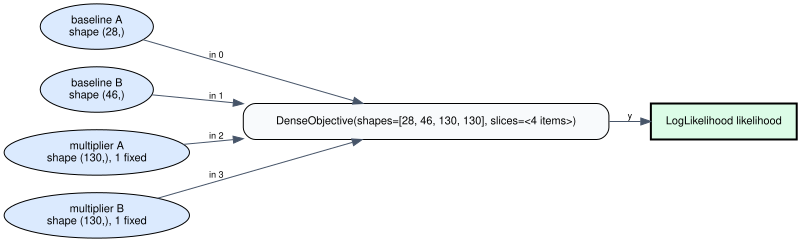

In [4]:
days = np.arange(hist["time"].min().floor("D"), t0.floor("D") + pd.Timedelta(days=1),
                 dtype="datetime64[D]")
edges = [np.concatenate([[hist["time"].min().to_datetime64()],
                         np.sort(hist.loc[hist.ladder == lad, "deadline"].unique())])
         for lad in ("blockade", "ceasefire")]
history = pm.FactorHistory(hist, edges, days, lam_m=5.).fit()
mA, mB = history.multipliers()
print("%d prices, %d parameters" % (history.q.size, history.P))
history.mle.graph()

The graph is short because the model is one `DenseObjective` node: the
structure is inside its objective and derivatives.

**Exact derivatives.** Gradient and Hessian against central finite
differences, at a random point:

In [5]:
def fd_check(fn, theta, idx, h=1e-5):
    v, g, H = fn(theta)
    eg = eh = 0.
    for i in idx:
        e = np.zeros_like(theta); e[i] = h
        vp, gp, _ = fn(theta + e); vm, gm, _ = fn(theta - e)
        eg = max(eg, abs((vp - vm) / (2 * h) - g[i]) / (1 + abs(g[i])))
        eh = max(eh, np.max(np.abs((gp - gm) / (2 * h) - H[i]) / (1 + np.abs(H[i]))))
    return eg, eh

theta = history.start() + np.random.default_rng(0).normal(0, .1, history.P)
print("history model: relative error gradient %.1e, Hessian %.1e"
      % fd_check(history.objective, theta, range(0, history.P, 5)))

history model: relative error gradient 4.9e-09, Hessian 2.0e-10


mean absolute error 0.032, 95% quantile 0.094


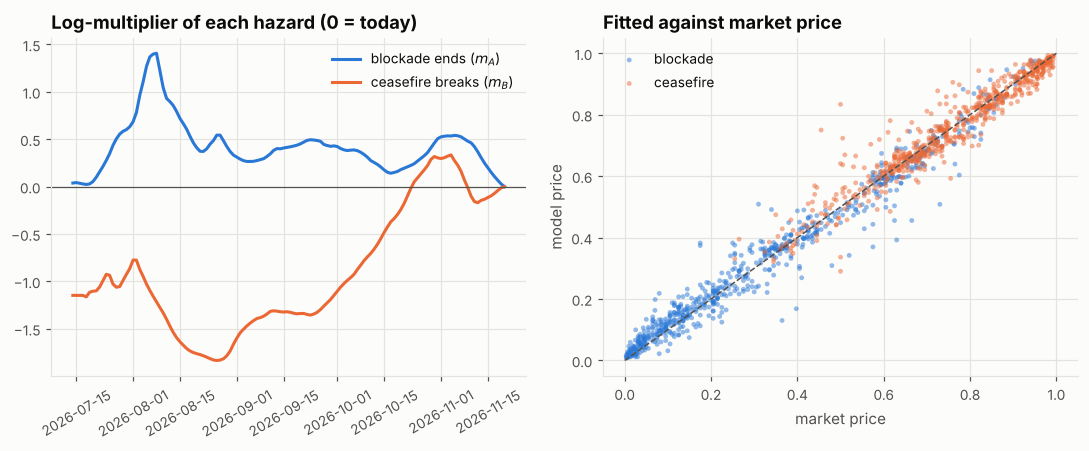

In [6]:
fitted = history.fitted_prices()
fig, axes = plt.subplots(1, 2, figsize=(10, 4.2))
ax = axes[0]
ax.plot(days, mA, color=BLUE, label="blockade ends ($m_A$)")
ax.plot(days, mB, color=ORANGE, label="ceasefire breaks ($m_B$)")
ax.axhline(0, color=TEXT_2, lw=0.8)
ax.set_title("Log-multiplier of each hazard (0 = today)")
ax.tick_params(axis="x", rotation=30)
ax.legend()
ax = axes[1]
for s, (label, color) in enumerate((("blockade", BLUE), ("ceasefire", ORANGE))):
    o = history.ladder == s
    ax.scatter(history.q[o], fitted[o], s=10, alpha=.5, color=color, label=label,
               edgecolor="none")
ax.plot([0, 1], [0, 1], color=TEXT_2, lw=1, ls="--")
ax.set_title("Fitted against market price")
ax.set_xlabel("market price"); ax.set_ylabel("model price")
ax.legend()
plt.tight_layout()
err = np.abs(fitted - history.q)
print("mean absolute error %.3f, 95%% quantile %.3f" % (err.mean(), np.quantile(err, .95)))

A single multiplier per day and ladder reproduces some 1,300 prices within 3
points on average: most of the daily movement of each ladder is a shift of the
whole hazard curve.

- **Blockade**: the hazard peaked at the start of August, when an end was
  priced as imminent, then fell as it kept being postponed; it dropped again
  in November.
- **Ceasefire**: the hazard was lowest in August, rose through September and
  October (the "holds through 31 December" contract fell to about 0.35), fell
  in early November when the prices jumped back up, and has edged up in the
  last days.

### 3.2 Temporal structure of the factor

For a random walk, the variance of an $h$-day change grows like $h$; for a
mean-reverting factor it levels off. Standard deviation of the change per
$\sqrt{h}$, and the correlation between the changes of the two multipliers:

,sd A / sqrt(h),sd B / sqrt(h),corr,corr 95% low,corr 95% high
h (days),,,,,
1,0.051,0.044,-0.042,-0.222,0.141
3,0.083,0.072,0.023,-0.296,0.337
7,0.106,0.097,0.145,-0.378,0.598
14,0.114,0.119,0.204,-0.620,0.814
21,0.094,0.126,0.112,-0.887,0.926
28,0.068,0.125,0.118,-0.951,0.969


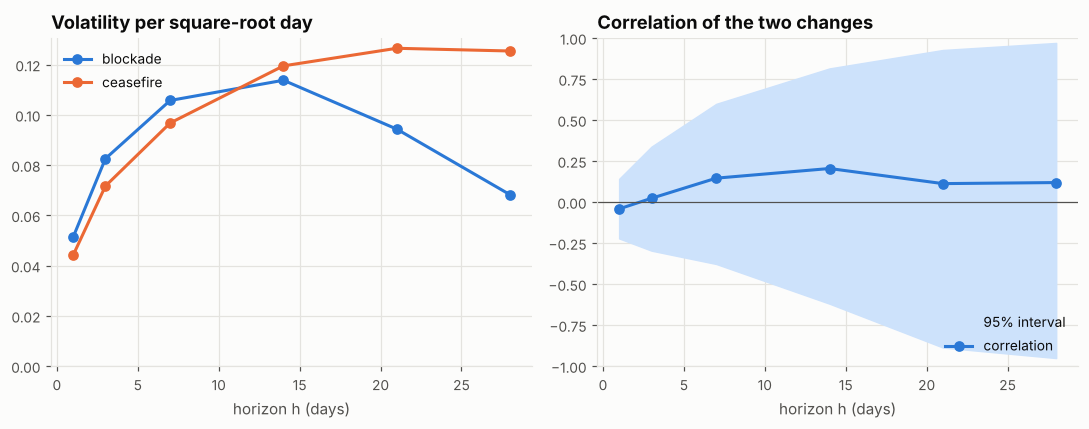

In [7]:
obs = hist.assign(day=hist["time"].dt.floor("D")).groupby(["day", "ladder"]).size().unstack()
both = obs.reindex(pd.DatetimeIndex(days)).notna().all(axis=1).values
rows = []
for h in (1, 3, 7, 14, 21, 28):
    ok = both[h:] & both[:-h]
    a, b = (mA[h:] - mA[:-h])[ok], (mB[h:] - mB[:-h])[ok]
    n_indep = ok.sum() / h                     # roughly independent changes
    r = np.corrcoef(a, b)[0, 1]
    half = 1.96 / np.sqrt(max(n_indep - 3, 1))
    rows.append((h, a.std() / np.sqrt(h), b.std() / np.sqrt(h), r,
                 np.tanh(np.arctanh(r) - half), np.tanh(np.arctanh(r) + half)))
temporal = pd.DataFrame(rows, columns=["h (days)", "sd A / sqrt(h)", "sd B / sqrt(h)",
                                       "corr", "corr 95% low", "corr 95% high"]).set_index("h (days)")

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
ax = axes[0]
ax.plot(temporal.index, temporal["sd A / sqrt(h)"], "o-", color=BLUE, label="blockade")
ax.plot(temporal.index, temporal["sd B / sqrt(h)"], "o-", color=ORANGE, label="ceasefire")
ax.set_ylim(0, None)
ax.set_title("Volatility per square-root day")
ax.set_xlabel("horizon h (days)")
ax.legend()
ax = axes[1]
ax.fill_between(temporal.index, temporal["corr 95% low"], temporal["corr 95% high"],
                color="#cde2fb", label="95% interval")
ax.plot(temporal.index, temporal["corr"], "o-", color=BLUE, label="correlation")
ax.axhline(0, color=TEXT_2, lw=0.8)
ax.set_ylim(-1, 1)
ax.set_title("Correlation of the two changes")
ax.set_xlabel("horizon h (days)")
ax.legend(loc="lower right")
plt.tight_layout()
temporal.round(3)

- The volatility per $\sqrt{h}$ rises up to about a week (in part an effect of
  the random-walk penalty, which smooths the day-to-day steps), then:
  - **ceasefire**: it stays flat up to 28 days, as for a random walk;
  - **blockade**: it falls after two weeks, a sign of mean reversion (the
    announcement kept being priced as near, then postponed). There are few
    independent months to confirm it.
- The correlation of the changes of $\hat m_A$ and $\hat m_B$, computed
  directly, is small and positive, with wide intervals. This two-step number is
  biased towards zero (see the theory), so the next section estimates the
  correlation as a parameter of the model.

### 3.3 The correlation as a parameter

Maximum likelihood of the state-space model, then the profile likelihood of
$\rho$: the other three parameters are re-estimated for each fixed $\rho$.

sA 0.146, sB 0.204 per day; price noise tau 0.036
rho -0.44, 95% interval about [-0.60, -0.25]; rho = 0: LR 12.7, p = 0.0004


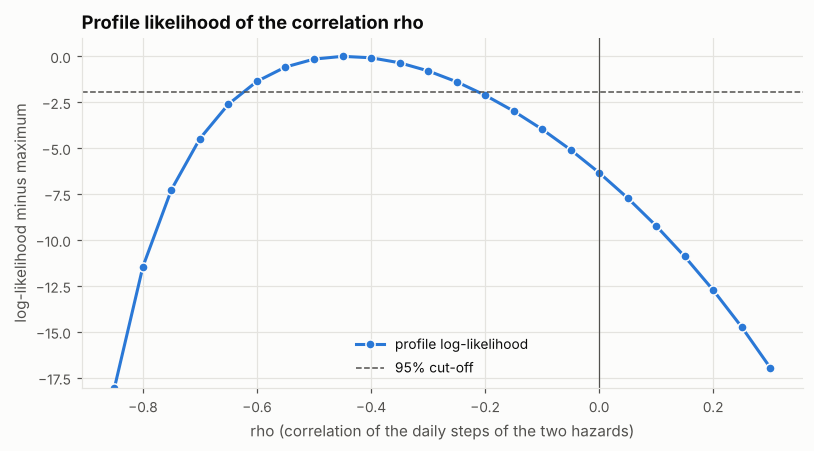

In [8]:
space = pm.FactorStateSpace(history)
state = space.fit()
grid = np.round(np.arange(-0.85, 0.31, 0.05), 2)
profile = pd.Series({r: space.fit(rho=r)["loglik"] for r in grid}) - state["loglik"]
inside = profile[profile > -1.92].index          # 95%: likelihood ratio < 3.84
lr_zero = -2 * profile.loc[0.0]
from scipy.stats import chi2
print("sA %.3f, sB %.3f per day; price noise tau %.3f" % (state["sA"], state["sB"], state["tau"]))
print("rho %.2f, 95%% interval about [%.2f, %.2f]; rho = 0: LR %.1f, p = %.4f"
      % (state["rho"], inside.min(), inside.max(), lr_zero, chi2.sf(lr_zero, 1)))

fig, ax = plt.subplots()
ax.plot(profile.index, profile.values, "o-", color=BLUE, markersize=6,
        markeredgecolor="#fcfcfb", label="profile log-likelihood")
ax.axhline(-1.92, color=TEXT_2, lw=1, ls="--", label="95% cut-off")
ax.axvline(0, color=TEXT_2, lw=0.8)
ax.set_ylim(max(profile.min(), -25), 1)
ps.finish(ax, "Profile likelihood of the correlation rho",
          "rho (correlation of the daily steps of the two hazards)",
          "log-likelihood minus maximum", legend=True)

With the price noise modelled ($\tau \approx 3.6$ points) the correlation is
**negative and clearly different from zero**: when the hazard of an
announcement rises, the hazard of a breakdown falls, and the other way round.
That fits one driver, escalation against de-escalation, behind both markets.
The two-step estimate had the wrong sign, and its step volatilities were about
three times too small, both from over-smoothing.

*Caveat: the baselines $\hat a$ are held at the values of the penalised fit of
3.1, so the uncertainty of $\hat a$ is not propagated.*

### 3.4 Curves without the noise, and what can be predicted

Given the estimated parameters the states are Gaussian, and conditioning on
the prices is exact:

- **smoothed** states use the whole history, to reconstruct each day's hazard
  curve without the noise;
- **filtered** states use only the prices up to each day: what one would have
  known in real time.

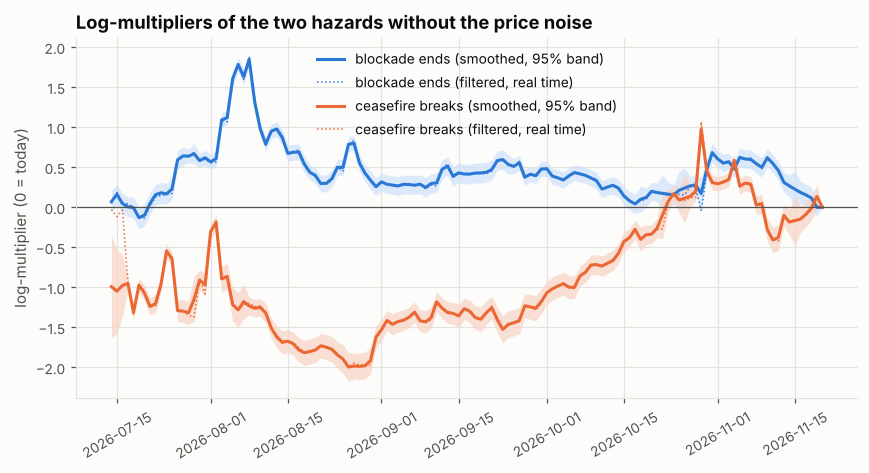

In [9]:
est = {k: state[k] for k in ("sA", "sB", "rho", "tau")}
smooth, smooth_sd = space.posterior(est, np.arange(space.D))
filt = space.filtered(est)

fig, ax = plt.subplots(figsize=(8, 4.4))
for k, (label, color, band) in enumerate((("blockade ends", BLUE, "#cde2fb"),
                                          ("ceasefire breaks", ORANGE, "#f9d3c2"))):
    ax.fill_between(days, smooth[k] - 1.96 * smooth_sd[k], smooth[k] + 1.96 * smooth_sd[k],
                    color=band, alpha=.7, lw=0)
    ax.plot(days, smooth[k], color=color, label=label + " (smoothed, 95% band)")
    ax.plot(days, filt[k], color=color, lw=1, ls=":", label=label + " (filtered, real time)")
ax.axhline(0, color=TEXT_2, lw=0.8)
ax.tick_params(axis="x", rotation=30)
ps.finish(ax, "Log-multipliers of the two hazards without the price noise",
          None, "log-multiplier (0 = today)", legend=True)

**Where will the prices go?** In a random walk the expected value of $m$
tomorrow is its value today: the model gives no direction for the factor,
as expected of an efficient market. Two parts of a price are predictable,
though:

1. **Time passing.** With no event, a "holds through" contract rises and a
   "by date" contract falls as the days go by; the hazard curve says by how much.
2. **Noise.** A contract that sits away from the curve of its ladder should
   move back towards it.

Test of the second, without looking ahead: on each day the model price of
every contract comes from the **filtered** state of that day. Does the gap
between that price and the market price predict the change of the market price
the next day?

           pairs of days    n  slope  std_error
                     all 1163  0.510      0.052
gap larger than 2 points  460  0.504      0.069


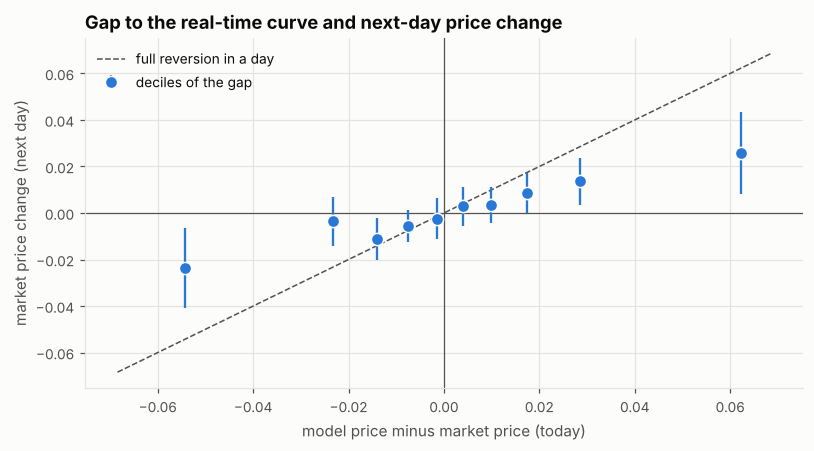

In [10]:
H = np.exp(space.logC + filt[space.ladder, space.day])
model_price = np.where(space.ladder == 0, -np.expm1(-H), np.exp(-H))
panel = history.data.assign(q=space.q, model=model_price, gap=model_price - space.q,
                            day=space.day).sort_values(["ladder", "deadline", "day"])
grp = panel.groupby(["ladder", "deadline"])
panel["next_change"] = grp["q"].shift(-1) - panel["q"]
panel["step"] = grp["day"].shift(-1) - panel["day"]
test = panel[panel["step"] == 1].dropna(subset=["next_change"])

def slope(x, y):
    b = np.polyfit(x, y, 1)[0]
    resid = y - np.polyval(np.polyfit(x, y, 1), x)
    se = np.sqrt(resid.var() / ((x - x.mean()) ** 2).sum())
    return b, se

rows = []
for name, sub in (("all", test), ("gap larger than 2 points", test[test["gap"].abs() > .02])):
    b, se = slope(sub["gap"].values, sub["next_change"].values)
    rows.append({"pairs of days": name, "n": len(sub), "slope": b, "std_error": se})
print(pd.DataFrame(rows).round(3).to_string(index=False))

bins = pd.qcut(test["gap"], 10)
g = test.groupby(bins, observed=True)
fig, ax = plt.subplots()
ax.axhline(0, color=TEXT_2, lw=0.8); ax.axvline(0, color=TEXT_2, lw=0.8)
lim = np.abs(g["gap"].mean()).max() * 1.1
ax.plot([-lim, lim], [-lim, lim], color=TEXT_2, lw=1, ls="--", label="full reversion in a day")
ax.errorbar(g["gap"].mean(), g["next_change"].mean(),
            yerr=1.96 * g["next_change"].std() / np.sqrt(g["next_change"].count()),
            fmt="o", color=BLUE, markersize=8, elinewidth=1.5, markeredgecolor="#fcfcfb",
            label="deciles of the gap")
ps.finish(ax, "Gap to the real-time curve and next-day price change",
          "model price minus market price (today)", "market price change (next day)",
          legend=True)

About half of the gap to the real-time curve closes the next day, also for
gaps larger than 2 points. Before reading this as a trading signal:

- the history holds the **last trade** of the day, so part of the reversion is
  the bounce between bid and ask, which cannot be captured (spreads are about
  1 point on the liquid contracts);
- the baselines $\hat a$ were fitted on the whole history, a mild look-ahead;
- liquidity differs a lot between contracts (the February one has traded
  about $1,600 in total).

A proper test would use bid and ask quotes (the order-book history) and fit
the baselines in real time as well.

**Using the other curve.** With correlated steps
$\eta = (\Delta m_A, \Delta m_B) \sim \mathcal N(0, \Sigma)$, a jump of the ceasefire
curve says something about the blockade curve. Without fresh blockade prices,
the best estimate is the regression

$$
\mathbb E[\Delta m_A \mid \Delta m_B] = \frac{\Sigma_{AB}}{\Sigma_{BB}}\,\Delta m_B = \rho\,\frac{s_A}{s_B}\,\Delta m_B ,
$$

and in price $\Delta p \approx \pm H e^{-H}\,\Delta m$ for each contract. With
prices of both curves, the filter weighs the two sources,
$\mathbb E[\eta \mid y] = \Sigma(\Sigma + R)^{-1} y$, with $R$ the noise of
the observations of each curve.

If one curve jumps and the other does not, should the other follow later? Only
if its market is slow: when both react to the same news at once, the curve that
did not move carries information too, and nothing is left to predict. Test:

1. on each day, filter each curve from its own prices only ($\rho = 0$) and
   from both curves ($\rho$ estimated);
2. the difference is the part of the curve that only the other curve explains
   (the *cross gap*);
3. regress each contract's next-day price change on its gap to its own curve
   and on the cross gap;
4. at the level of the factors, regress the next-day steps of each curve
   (own-price filter) on the previous steps of both, at lags of 1 to 3 days.

In [11]:
beta = state["rho"] * state["sA"] / state["sB"]
print("cross beta %.3f: a step of +1 in the ceasefire log-hazard moves the blockade "
      "log-hazard by %.2f on average" % (beta, beta))
own = space.filtered(dict(est, rho=0.))

def model_prices(m):
    H = np.exp(space.logC + m[space.ladder, space.day])
    return np.where(space.ladder == 0, -np.expm1(-H), np.exp(-H))

p_joint, p_own = model_prices(filt), model_prices(own)
panel = history.data.assign(q=space.q, own_gap=p_own - space.q, cross_gap=p_joint - p_own,
                            day=space.day, lad=space.ladder).sort_values(["ladder", "deadline", "day"])
grp = panel.groupby(["ladder", "deadline"])
panel["next_change"] = grp["q"].shift(-1) - panel["q"]
panel["step"] = grp["day"].shift(-1) - panel["day"]
test = panel[panel["step"] == 1].dropna(subset=["next_change"])

def ols(X, y):
    X = np.column_stack([np.ones(len(y)), X])
    b, *_ = np.linalg.lstsq(X, y, rcond=None)
    e = y - X @ b
    return b[1:], np.sqrt(np.diag(np.linalg.inv(X.T @ X) * e.var()))[1:]

rows = []
for name, sub in (("blockade contracts", test[test.lad == 0]),
                  ("ceasefire contracts", test[test.lad == 1]), ("all", test)):
    b, se = ols(sub[["own_gap", "cross_gap"]].values, sub["next_change"].values)
    rows.append({"contracts": name, "n": len(sub), "own gap": b[0], "se own": se[0],
                 "cross gap": b[1], "se cross": se[1],
                 "sd of cross gap (points)": 100 * sub["cross_gap"].std()})
display(pd.DataFrame(rows).round(3))

dA, dB = np.diff(own[0]), np.diff(own[1])
ok1 = both[1:] & both[:-1]
rows = []
for lag in (1, 2, 3):
    ok = ok1[lag:] & ok1[:-lag]
    for target, y, x_own, x_other in (("blockade", dA, dA, dB), ("ceasefire", dB, dB, dA)):
        b, se = ols(np.column_stack([x_own[:-lag][ok], x_other[:-lag][ok]]), y[lag:][ok])
        rows.append({"lag (days)": lag, "next step of": target, "own step": b[0],
                     "se own": se[0], "other curve's step": b[1], "se other": se[1]})
pd.DataFrame(rows).round(3)

cross beta -0.317: a step of +1 in the ceasefire log-hazard moves the blockade log-hazard by -0.32 on average


,contracts,n,own gap,se own,cross gap,se cross,sd of cross gap (points)
0,blockade contracts,607,0.396,0.064,-2.448,1.089,0.207
1,ceasefire contracts,556,0.842,0.078,2.084,1.079,0.228
2,all,1163,0.511,0.052,-0.036,0.809,0.217


,lag (days),next step of,own step,se own,other curve's step,se other
0,1,blockade,0.081,0.100,0.033,0.077
1,1,ceasefire,-0.075,0.099,-0.033,0.128
2,2,blockade,0.154,0.100,0.125,0.078
3,2,ceasefire,-0.140,0.099,-0.145,0.127
4,3,blockade,0.008,0.103,-0.006,0.080
5,3,ceasefire,0.028,0.100,0.064,0.128


At a daily resolution, **the other curve does not predict a catch-up**:

- the cross gap is tiny (about 0.2 points): each ladder has several contracts
  a day, and its own prices dominate its filtered curve;
- its coefficients are about two standard errors from zero but with
  **opposite signs** in the two ladders: for the blockade the price moves
  *away* from what the other curve implies, for the ceasefire towards it.
  Pooled they are zero, and on a gap of 0.2 points either effect is worth a
  fraction of a point: no consistent catch-up;
- at the level of the factors, no lag of the other curve's steps is
  significant.

The two markets react to the common news **on the same day**. A delayed
reaction, if there is one, would be within the day: testing it needs the hourly
or minute price histories (the API serves them), with the same model on a finer
time step.

### 3.5 Forward: joint law of the two events

Daily covariance from the state-space estimate; 4,000 paths of 6-hour steps.
The baselines are refitted so the averages over paths match today's prices.

In [12]:
sA, sB, rho_hat = state["sA"], state["sB"], state["rho"]
Sigma = np.array([[sA ** 2, rho_hat * sA * sB], [rho_hat * sA * sB, sB ** 2]])
print("daily covariance of the multipliers (state-space estimate):\n", Sigma.round(4))
forward = pm.FactorForward(t0, deadlines, Sigma, n_paths=4000).fit([qA, qB])
print("max gap to today's prices: %.1e" % max(
    np.abs(forward.marginal(0, forward.a[0]) - qA).max(),
    np.abs(forward.marginal(1, forward.a[1]) - qB).max()))

def fn_forward(a):
    p, dp, d2p = forward.marginal(0, a, True)
    return pm.binomial_kl(qA, p, dp, d2p)
print("forward model: relative error gradient %.1e, Hessian %.1e"
      % fd_check(fn_forward, forward.a[0] + 0.1, range(6)))

daily covariance of the multipliers (state-space estimate):
 [[ 0.0213 -0.0132]
 [-0.0132  0.0418]]


max gap to today's prices: 7.9e-10
forward model: relative error gradient 1.6e-11, Hessian 5.2e-11


**Blockade given the ceasefire.** Probability that the blockade ends by each
date, given that the ceasefire breaks by 30 November or holds through it:

In [13]:
fac = pm.factor_conditional_A(forward, 2)              # B deadline 2 = 30 Nov
fac_table = pd.DataFrame({"unconditional": qA, "ceasefire broken by 30 Nov": fac["broken"],
                          "ceasefire holds through 30 Nov": fac["holds"]},
                         index=pd.Index(date_label(A["deadline"], "%d %b %Y"), name="blockade ends by"))
fac_table.round(3)

,unconditional,ceasefire broken by 30 Nov,ceasefire holds through 30 Nov
blockade ends by,,,
30 Nov 2026,0.030,0.029,0.031
15 Dec 2026,0.075,0.071,0.076
31 Dec 2026,0.115,0.109,0.117
31 Jan 2027,0.225,0.214,0.227
28 Feb 2027,0.325,0.312,0.328
31 Mar 2027,0.435,0.422,0.438


With a common factor, conditioning on the ceasefire barely moves the blockade:
whether the ceasefire breaks in the next ten days depends mostly on the
randomness of the event itself, and only a little on the shared drivers.
With the estimated correlation, a breakdown by 30 November moves the March
probability by only a few points (table above; section 5 for the ends of the
interval of $\rho$). **A strong dependence between the
events needs a direct effect of one on the other**: the Markov model.

## 4. Model 2: four-state Markov chain

Again the marginals are fitted exactly, here for any $\rho$ and $\kappa$.

max gap to today's prices: 2.4e-09


Markov model: relative error gradient 9.8e-11, Hessian 1.5e-10


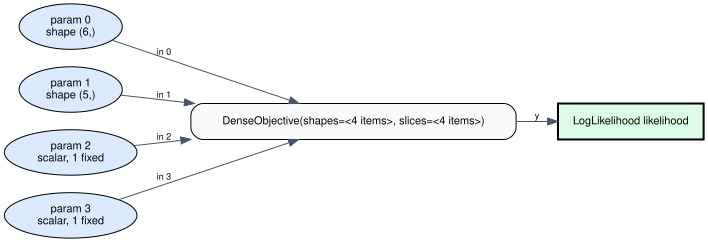

In [14]:
markov = pm.MarkovForward(t0, deadlines).fit([qA, qB], rho=1., kappa=1.)
pA, pB = markov.marginals(markov.theta, derivatives=False)
print("max gap to today's prices: %.1e" % max(np.abs(pA - qA).max(), np.abs(pB - qB).max()))

def fn_markov(theta):
    (pA, dA, d2A), (pB, dB, d2B) = markov.marginals(theta)
    vA, gA, HA = pm.binomial_kl(qA, pA, dA, d2A)
    vB, gB, HB = pm.binomial_kl(qB, pB, dB, d2B)
    return vA + vB, gA + gB, HA + HB
theta = markov.theta + np.concatenate([np.zeros(11), [np.log(.5), np.log(.7)]])
print("Markov model: relative error gradient %.1e, Hessian %.1e"
      % fd_check(fn_markov, theta, range(markov.P)))
markov.mle.graph()

**Scenarios.** $\rho$ is the factor by which a breakdown of the ceasefire
multiplies the hazard of an announcement; $\kappa$ the factor by which an end
of the blockade multiplies the hazard of a breakdown. For each pair the
baselines are refitted to today's prices, then:

In [15]:
rhos, kappas = [0.25, 0.5, 1., 2.], [0.5, 1., 2.]
rows = []
for rho in rhos:
    for kappa in kappas:
        m = pm.MarkovForward(t0, deadlines).fit([qA, qB], rho=rho, kappa=kappa)
        c = m.conditional_A(2)
        rows.append({"rho": rho, "kappa": kappa,
                     "P(ended by 31 Mar | broken by 30 Nov)": c["broken"][5],
                     "P(ended by 31 Mar | holds through 30 Nov)": c["holds"][5],
                     "P(holds through 31 Dec | ended by 15 Dec)": pm.markov_conditional_B(m, 1, 4)})
scen = pd.DataFrame(rows)
scen.round(3)

,rho,kappa,P(ended by 31 Mar | broken by 30 Nov),P(ended by 31 Mar | holds through 30 Nov),P(holds through 31 Dec | ended by 15 Dec)
0,0.25,0.5,0.220,0.478,0.837
1,0.25,1.0,0.221,0.477,0.750
2,0.25,2.0,0.226,0.476,0.617
3,0.50,0.5,0.318,0.458,0.798
4,0.50,1.0,0.321,0.458,0.714
5,0.50,2.0,0.326,0.457,0.587
6,1.00,0.5,0.431,0.436,0.732
7,1.00,1.0,0.435,0.435,0.655
8,1.00,2.0,0.442,0.434,0.536
9,2.00,0.5,0.547,0.413,0.634


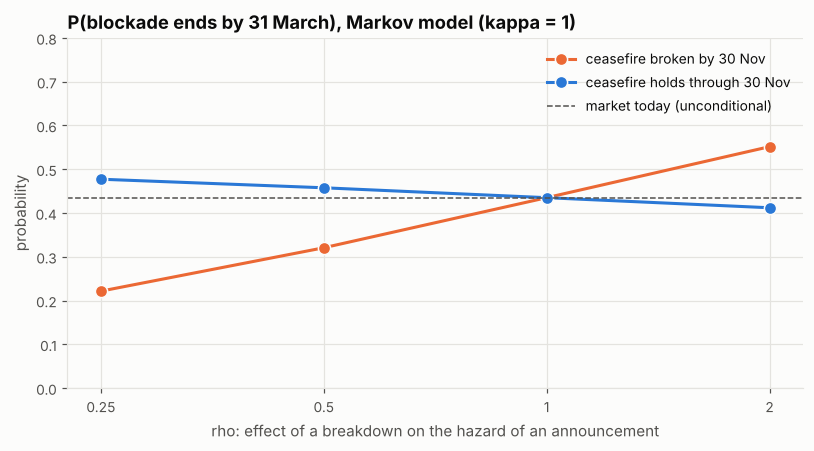

In [16]:
fig, ax = plt.subplots()
k1 = scen[scen.kappa == 1.]
ax.plot(k1["rho"], k1["P(ended by 31 Mar | broken by 30 Nov)"], "o-", color=ORANGE,
        markersize=8, markeredgecolor="#fcfcfb", label="ceasefire broken by 30 Nov")
ax.plot(k1["rho"], k1["P(ended by 31 Mar | holds through 30 Nov)"], "o-", color=BLUE,
        markersize=8, markeredgecolor="#fcfcfb", label="ceasefire holds through 30 Nov")
ax.axhline(qA[-1], color=TEXT_2, lw=1, ls="--", label="market today (unconditional)")
ax.set_xscale("log", base=2)
ax.set_xticks(rhos); ax.set_xticklabels(["%g" % r for r in rhos])
ax.set_ylim(0, 0.8)
ps.finish(ax, "P(blockade ends by 31 March), Markov model (kappa = 1)",
          "rho: effect of a breakdown on the hazard of an announcement", "probability",
          legend=True)

In the Markov model the scenario matters: with $\rho = 0.25$ a breakdown by 30
November cuts the probability of an announcement by March from about 44% to
about 22%; with $\rho = 2$ it raises it to about 55%. The probability given
that the ceasefire holds moves much less, because holding is the likely case
and the unconditional price must be preserved.

## 5. The two models side by side

The Markov $\rho$ and $\kappa$ that reproduce the dependence of the factor
model (same conditional probabilities), for the estimated correlation and the
ends of its 95% interval:

In [17]:
s = np.sqrt(np.diag(Sigma))
rows = []
for r in (inside.min(), state["rho"], inside.max()):
    S = np.array([[s[0] ** 2, r * s[0] * s[1]], [r * s[0] * s[1], s[1] ** 2]])
    f = pm.FactorForward(t0, deadlines, S, n_paths=4000).fit([qA, qB])
    cA, cB = pm.factor_conditional_A(f, 2), pm.factor_conditional_B(f, 1, 4)
    gapA = lambda lr: pm.MarkovForward(t0, deadlines).fit(
        [qA, qB], rho=np.exp(lr)).conditional_A(2)["broken"][5] - cA["broken"][5]
    lr = brentq(gapA, -3, 3, xtol=1e-3)
    gapB = lambda lk: pm.markov_conditional_B(pm.MarkovForward(t0, deadlines).fit(
        [qA, qB], rho=np.exp(lr), kappa=np.exp(lk)), 1, 4) - cB
    lk = brentq(gapB, -3, 3, xtol=1e-3)
    rows.append({"factor correlation": r,
                 "P(ended by 31 Mar | broken by 30 Nov)": cA["broken"][5],
                 "P(ended by 31 Mar | holds)": cA["holds"][5],
                 "P(holds through 31 Dec | ended by 15 Dec)": cB,
                 "equivalent rho": np.exp(lr), "equivalent kappa": np.exp(lk)})
pd.DataFrame(rows).round(3)

,factor correlation,P(ended by 31 Mar | broken by 30 Nov),P(ended by 31 Mar | holds),P(holds through 31 Dec | ended by 15 Dec),equivalent rho,equivalent kappa
0,-0.600,0.417,0.439,0.693,0.901,0.817
1,-0.443,0.422,0.438,0.684,0.925,0.857
2,-0.250,0.427,0.437,0.673,0.955,0.911


## 6. Conclusions

- **Each ladder is coherent on its own.** Both term structures convert to
  positive hazards at every step. The ceasefire market prices a spike of risk
  in the next few days.
- **Model 1 (latent factor).** One multiplier per day and ladder explains the
  history well. The ceasefire factor moves like a random walk; the blockade
  factor shows some mean reversion beyond two weeks.
  - Estimated as a parameter of a state-space model, with the price noise
    apart, the steps of the two hazards are **negatively correlated** (about
    −0.45, clearly different from zero): one escalation/de-escalation driver
    behind both markets. The direct correlation of the smoothed series missed
    it.
  - Through shared drivers, even this correlation changes the conditional
    prices only by a few points, so the equivalent Markov $\rho$ and $\kappa$
    stay fairly close to 1.
- **Model 2 (Markov).** A direct effect of one event on the other can move the
  conditional prices a lot, but **today's prices cannot tell $\rho$ and
  $\kappa$**: the marginals are reproduced exactly for any values. The history
  does not tell them either, since neither event has happened yet.
  - These parameters are a judgement call: what a breakdown would do to the
    negotiations. The model turns that judgement into prices that are coherent
    with both ladders.
- **Denoised curves and prediction.** The state-space model reconstructs each
  day's hazard curves without the noise and in real time. It gives no
  direction for the factor (a random walk). Contracts away from the real-time
  curve move about halfway back the next day; part of this is the bid–ask
  bounce of last-trade prices. At a daily resolution the other curve adds
  no prediction: both markets absorb the common news on the same day.
- **In practice:**
  - the hazard curves flag incoherent contracts within a ladder (none today);
  - the factor model gives the co-movement for hedging one ladder with the
    other;
  - the Markov model prices "what if the ceasefire breaks" scenarios once
    $\rho$ is chosen.

*This is an illustration of the models, not trading advice.*